
# FlashPoint: staged spatiotemporal position reconstruction

Supports:

$$
N_{\rm EDGE}=0,1,2,3,4,5,12,24
\quad\Rightarrow\quad
4,8,12,16,20,24,52,100\ {\rm SiPMs}.
$$

Study order:

1. Conventional COG baselines;
2. full-amplitude template likelihood;
3. amplitude + first-photon timing;
4. amplitude + first-3-photon timing;
5. amplitude + early-photon \(dN/dt\);
6. full binned spatiotemporal Poisson likelihood;
7. optional ExtraTrees nonlinear baseline;
8. approximate Fisher-information / CRLB check for the \(\sim10\) mm target.

Timing is aligned event-by-event to the **earliest detected photon in the whole detector**, so the reconstruction uses relative timing rather than the unknown absolute event time.

The early \(dN/dt\) representation is first built at **50 ps/bin** and rebinned to **100 ps/bin** for the main reconstruction. Change the configuration below if memory is limited.


### Revision notes
The original study order, detector geometry, split fraction, estimators and plotting style are retained.
Changes include validated hit/amplitude alignment, bounded feature construction, sparse ST counts,
an amplitude-only HGB control, and corrected optional-study/CRLB/map handling.
All optional studies are controlled in the configuration cell below.

Dependencies: NumPy, pandas, SciPy, Matplotlib, uproot, scikit-learn and IPython.
Edit `RUN`/`INDIR` for your data and `OUT` for results, then run from a fresh kernel.
Loading reads one complete hit file at a time; the fine histogram still uses RAM proportional
to the total event count. HGB with thousands of timing features remains expensive.

Comparisons use a random **event** split, not an independent run or position split.
Inspect `coverage` as well as resolution: corner COG may be undefined on some events.
Selecting the best method or scan setting on this test sample is exploratory;
use a separate validation sample and final untouched test sample for a confirmed result.
Local bias/RMSE use the per-coordinate RMS convention, not radial magnitude.
The event-aligned ST Poisson likelihood is a working approximation, not a validated independent-count model.

In [164]:

# 0. Imports + configuration
from pathlib import Path
import warnings
from scipy import sparse
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor

SEED=42

# NEDGE = 0, 1, 2, 3, 4, 5, 12, 24 -> 4, 8, 12, 16, 20, 24, 52, 100 SiPMs
NEDGE=24
LENGTH=1000 # detector size [mm]
HALF=LENGTH/2

# detector timing smearing
APPLY_TIMING_SMEARING=True
TIMING_SIGMA_PS=300       # Gaussian sigma [ps], not FWHM

# ------------------------------------
# nominal study with 1 m detector and varying number of SiPMs
RUN=Path(f"/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_{LENGTH}")
INDIR=RUN/f"output_edge{NEDGE}"
OUT=RUN/f"output_edge{NEDGE}_spatiotemporal"; OUT.mkdir(parents=True,exist_ok=True)
FILES=sorted(INDIR.glob("*.root"))

if not FILES:
    raise FileNotFoundError(f"No ROOT files found in {INDIR}")

NSIPM=4+4*NEDGE
TRAIN_FRAC=.70

# spatial response templates
GRID_N=40                 # 40x40 -> nominal 25 mm cells over 1 m
MIN_CELL=10
POSTERIOR_K=9             # local interpolation from best K template cells
LIKELIHOOD_CHUNK=2000
FEATURE_CHUNK=2000       # bound temporary feature/template allocations
HIST_DTYPE=np.uint16      # overflow is checked before casting

# early dN/dt
DT_FINE_NS=.05            # 50 ps master bin
EARLY_NS=3.0
DND_REBIN=2               # main reconstruction: 100 ps/bin
NBIN_FINE=int(round(EARLY_NS/DT_FINE_NS))

# nonlinear regression
HGB_MAX_ITER=180
HGB_LEAVES=31
ML_TRAIN_MAX=100_000

# optional expensive studies
RUN_EXTRA_TREES=True
RUN_TIMING_BIN_SCAN=False
RUN_TRUE_TIMING_SCAN=False
SIGMA_T_PS=[0,50,100,150,200,250,300,400,500,750,1000]

if NEDGE not in (0,1,2,3,4,5,12,24):
    raise ValueError("Unsupported NEDGE")
if not (0<TRAIN_FRAC<1) or GRID_N<2 or MIN_CELL<1:
    raise ValueError("Invalid split/grid settings")
if DT_FINE_NS<=0 or EARLY_NS<=0 or not np.isclose(NBIN_FINE*DT_FINE_NS,EARLY_NS):
    raise ValueError("EARLY_NS must be a positive exact multiple of DT_FINE_NS")
if TIMING_SIGMA_PS<0 or POSTERIOR_K<1 or min(LIKELIHOOD_CHUNK,FEATURE_CHUNK,ML_TRAIN_MAX)<1:
    raise ValueError("Invalid timing, interpolation, chunk or training settings")

print(f"NEDGE={NEDGE} -> NSIPM={NSIPM}")
print(f"ROOT files={len(FILES)}")
print(f"dN/dt master bin={DT_FINE_NS*1e3:.0f} ps, main bin={DT_FINE_NS*DND_REBIN*1e3:.0f} ps")
print(f"Timing smearing: {APPLY_TIMING_SMEARING}, sigma={TIMING_SIGMA_PS} ps")


NEDGE=24 -> NSIPM=100
ROOT files=27
dN/dt master bin=50 ps, main bin=100 ps
Timing smearing: True, sigma=300 ps


SiPM  0: (  497.854,  497.854) mm
SiPM  1: ( -497.854,  497.854) mm
SiPM  2: ( -497.854, -497.854) mm
SiPM  3: (  497.854, -497.854) mm
SiPM  4: ( -458.026,  497.854) mm
SiPM  5: ( -418.197,  497.854) mm
SiPM  6: ( -378.369,  497.854) mm
SiPM  7: ( -338.541,  497.854) mm
SiPM  8: ( -298.712,  497.854) mm
SiPM  9: ( -258.884,  497.854) mm
SiPM 10: ( -219.056,  497.854) mm
SiPM 11: ( -179.227,  497.854) mm
SiPM 12: ( -139.399,  497.854) mm
SiPM 13: (  -99.571,  497.854) mm
SiPM 14: (  -59.742,  497.854) mm
SiPM 15: (  -19.914,  497.854) mm
SiPM 16: (   19.914,  497.854) mm
SiPM 17: (   59.742,  497.854) mm
SiPM 18: (   99.571,  497.854) mm
SiPM 19: (  139.399,  497.854) mm
SiPM 20: (  179.227,  497.854) mm
SiPM 21: (  219.056,  497.854) mm
SiPM 22: (  258.884,  497.854) mm
SiPM 23: (  298.712,  497.854) mm
SiPM 24: (  338.541,  497.854) mm
SiPM 25: (  378.369,  497.854) mm
SiPM 26: (  418.197,  497.854) mm
SiPM 27: (  458.026,  497.854) mm
SiPM 28: (  497.854,  458.026) mm
SiPM 29: (  49

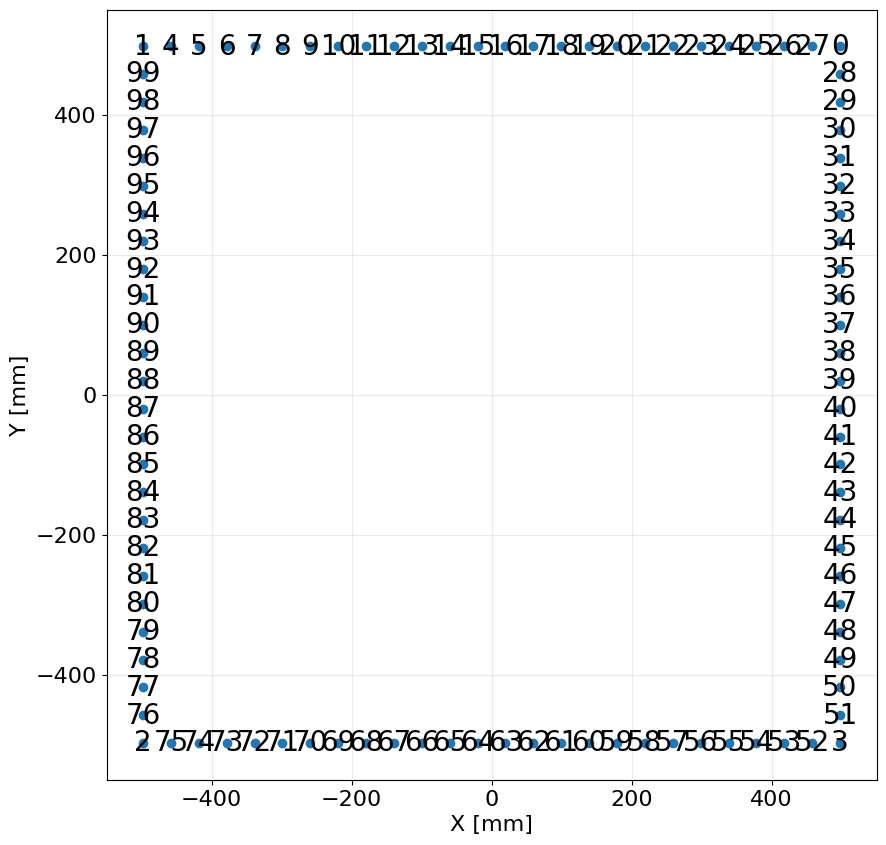

In [165]:

# 1. Exact SiPM optical-contact positions used for conventional COG
def get_POS(NEDGE):
    EDGE = HALF - 2.1460690809
    pos = [[ EDGE, EDGE],[-EDGE, EDGE],[-EDGE,-EDGE],[ EDGE,-EDGE]]

    if NEDGE:
        u = np.linspace(-EDGE, EDGE, NEDGE+2)[1:-1]
        pos += [[ x, EDGE] for x in u]       # +Y: left -> right
        pos += [[EDGE,-y] for y in u]        # +X: top -> bottom
        pos += [[-x,-EDGE] for x in u]       # -Y: right -> left
        pos += [[-EDGE,y] for y in u]        # -X: bottom -> top

    return np.asarray(pos,float)

POS=get_POS(NEDGE)
assert len(POS)==NSIPM

for i,(x,y) in enumerate(POS):
    print(f"SiPM {i:2d}: ({x:9.3f},{y:9.3f}) mm")

fig,ax=plt.subplots(figsize=(12,10))
ax.scatter(POS[:,0],POS[:,1])
for i,(x,y) in enumerate(POS): ax.text(x,y,str(i),ha="center",va="center",fontsize=20)
ax.set(xlabel="X [mm]",ylabel="Y [mm]",aspect="equal",xlim=(-(HALF+50),HALF+50),ylim=(-(HALF+50),HALF+50))
# increase the font size for all axes labels and ticks
for item in ([ax.xaxis.label, ax.yaxis.label] + ax.get_xticklabels() + ax.get_yticklabels()):
    item.set_fontsize(16)
ax.grid(alpha=.25)
plt.show()



## 2. Load ROOT files and build timing features

To avoid keeping the full `hits` tree from every batch job in memory, each file is processed separately.

For each event and SiPM the notebook derives:

- detected photon count $N_i$;
- $t_{i,1},t_{i,2},t_{i,3}$, each relative to the earliest detected photon in the event;
- an early-photon $dN_i/dt$ histogram.

The event ordering of the timing arrays is kept exactly aligned with the concatenated `events` DataFrame.


In [166]:
# 2. Load events + derive T1/T2/T3 and 50-ps dN/dt file-by-file
TIME_NAMES=["t_plot_ns","t_ns","time_ns","arrival_time_ns","global_time_ns"]

def integer_ids(values,label):
    values=np.asarray(values)
    if not np.isfinite(values).all() or not np.equal(values,np.floor(values)).all():
        raise ValueError(f"{label} must contain finite integer IDs")
    return values.astype(np.int64)

def read_hit_arrays(f,local):
    if len(np.unique(local))!=len(local):
        raise ValueError("Duplicate local event IDs; hit-to-event mapping is ambiguous")
    if "hits" not in f:
        raise KeyError("Missing hits tree: timing studies require complete hit information")
    tree=f["hits"]
    thit=next((x for x in TIME_NAMES if x in tree.keys()),None)
    if thit is None:
        raise KeyError(f"No timing branch found; tried {TIME_NAMES}")
    h=tree.arrays(["event","sipm",thit],library="np")
    ev=integer_ids(h["event"],"hits.event")
    sipm=integer_ids(h["sipm"],"hits.sipm")
    tm=np.asarray(h[thit],dtype=np.float64)
    row=pd.Index(local).get_indexer(ev)
    if (row<0).any() or ((sipm<0)|(sipm>=NSIPM)).any() or not np.isfinite(tm).all():
        raise ValueError("Unmapped event, out-of-range SiPM or nonfinite hit time")
    return row,sipm,tm

def timing_features(row,sipm,tm,n,sigma_ps,rg,with_dnd=True):
    # Same jitter order as the input tree; order statistics are recomputed afterward.
    tm=tm.copy()
    if sigma_ps:
        tm+=rg.normal(0,sigma_ps/1000.,len(tm))
    t0=np.full(n,np.inf)
    np.minimum.at(t0,row,tm)
    dt=tm-t0[row]
    group=row*NSIPM+sipm
    order=np.lexsort((tm,group))
    gs=group[order]
    starts=np.flatnonzero(np.r_[True,gs[1:]!=gs[:-1]]) if len(gs) else np.empty(0,int)
    ends=np.r_[starts[1:],len(gs)]
    times=[]
    for k in range(3):
        target=np.full((n,NSIPM),np.nan,np.float32)
        take=starts[starts+k<ends]+k
        target.ravel()[gs[take]]=dt[order[take]]
        times.append(target)
    if not with_dnd:
        return (*times,None)
    dnd=np.zeros((n,NSIPM,NBIN_FINE),dtype=HIST_DTYPE)
    early=dt<EARLY_NS
    b=np.floor(dt[early]/DT_FINE_NS).astype(np.int64)
    inside=(b>=0)&(b<NBIN_FINE)
    flat=group[early][inside]*NBIN_FINE+b[inside]
    # Only count occupied bins: no dense int64 bincount temporary.
    occupied,count=np.unique(flat,return_counts=True)
    if len(count) and count.max()>np.iinfo(HIST_DTYPE).max:
        raise OverflowError("Histogram overflow: set HIST_DTYPE=np.uint32")
    dnd.ravel()[occupied]=count
    return (*times,dnd)

# Allocate once rather than keeping all file arrays plus a stacked duplicate.
file_sizes=[]
for fname in FILES:
    with uproot.open(fname) as f:
        file_sizes.append(int(f["events"].num_entries))
ntotal=sum(file_sizes)
T1=np.full((ntotal,NSIPM),np.nan,np.float32)
T2=np.full_like(T1,np.nan); T3=np.full_like(T1,np.nan)
DND_FINE=np.zeros((ntotal,NSIPM,NBIN_FINE),dtype=HIST_DTYPE)
E=[]; offset=0
rng_smear=np.random.default_rng(SEED+100)
for job,(fname,n) in enumerate(zip(FILES,file_sizes)):
    with uproot.open(fname) as f:
        e=pd.DataFrame(f["events"].arrays(library="np"))
        if len(e)!=n:
            raise ValueError(f"Event row count changed in {fname}")
        local=integer_ids(e["event"] if "event" in e else np.arange(n),"events.event")
        row,sipm,tm=read_hit_arrays(f,local)
        amplitude=e[[f"n_detected_sipm{i}" for i in range(NSIPM)]].to_numpy(float)
        hit_count=np.bincount(row*NSIPM+sipm,minlength=n*NSIPM).reshape(n,NSIPM)
        if not np.array_equal(amplitude,hit_count):
            raise ValueError(f"{fname.name}: hit counts disagree with amplitude branches; "
                             "check that hits contains exactly the detected photons")
        t1,t2,t3,dnd=timing_features(row,sipm,tm,n,
            TIMING_SIGMA_PS if APPLY_TIMING_SMEARING else 0,rng_smear)
        sl=slice(offset,offset+n)
        T1[sl]=t1; T2[sl]=t2; T3[sl]=t3; DND_FINE[sl]=dnd
        e["event_local"]=local; e["job"]=job
        e["event"]=np.arange(offset,offset+n)  # globally unique row IDs
        E.append(e); offset+=n
        print(f"{job:3d} {fname.name:42s} events={n:6d}")
        del row,sipm,tm,hit_count,amplitude,t1,t2,t3,dnd
events=pd.concat(E,ignore_index=True).replace([np.inf,-np.inf],np.nan)
del E,e
have_hits=True
assert len(events)==len(T1)==len(DND_FINE)
print("\nTotal events:",len(events))
print("DND_FINE shape:",DND_FINE.shape,f"({DND_FINE.nbytes/1024**2:.1f} MiB)")

  0 sipm_edge24_10.root                        events= 10000
  1 sipm_edge24_11.root                        events= 10000
  2 sipm_edge24_12.root                        events= 10000
  3 sipm_edge24_13.root                        events= 10000
  4 sipm_edge24_14.root                        events= 10000
  5 sipm_edge24_15.root                        events= 10000
  6 sipm_edge24_16.root                        events= 10000
  7 sipm_edge24_17.root                        events= 10000
  8 sipm_edge24_18.root                        events= 10000
  9 sipm_edge24_19.root                        events= 10000
 10 sipm_edge24_20.root                        events= 10000
 11 sipm_edge24_21.root                        events= 10000
 12 sipm_edge24_22.root                        events= 10000
 13 sipm_edge24_23.root                        events= 10000
 14 sipm_edge24_24.root                        events= 10000
 15 sipm_edge24_25.root                        events= 10000
 16 sipm_edge24_26.root 

In [167]:

# 3. Standardize truth + amplitude arrays
def first(df,names): return next((x for x in names if x in df),None)

X=first(events,["source_x_mm","x_source_mm","source_x","x_true_mm"])
Y=first(events,["source_y_mm","y_source_mm","source_y","y_true_mm"])
if X is None or Y is None:
    raise KeyError("Truth X/Y branches not found.")

truth=events[[X,Y]].to_numpy(float)
A=np.column_stack([
    events[f"n_detected_sipm{i}"].to_numpy(float)
    for i in range(NSIPM)
])

if not np.isfinite(A).all() or (A<0).any() or not np.equal(A,np.floor(A)).all():
    raise ValueError("Amplitude branches must contain finite nonnegative integer counts")
Ntot=A.sum(1)
F=A/np.where(Ntot[:,None]>0,Ntot[:,None],np.nan)
logN=np.log1p(Ntot)[:,None]

good=np.isfinite(truth).all(1)&(Ntot>0)&(np.abs(truth)<=HALF).all(1)
print("Excluded invalid/zero-photon/out-of-detector events:",int((~good).sum()))
events=events.loc[good].reset_index(drop=True)
truth=truth[good]; A=A[good]; F=F[good]; logN=logN[good]
if not good.all():
    T1=T1[good]; T2=T2[good]; T3=T3[good]; DND_FINE=DND_FINE[good]
Ntot=Ntot[good]

print("Usable events:",len(truth))
print("Mean detected photons/event:",Ntot.mean())
print("Mean corner-only photons/event:",A[:,:4].sum(1).mean())


Excluded invalid/zero-photon/out-of-detector events: 0
Usable events: 270000
Mean detected photons/event: 910.3027888888889
Mean corner-only photons/event: 36.917114814814816


In [168]:

# 4. Rebin early dN/dt + train/test split
def rebin_dnd(dnd,factor):
    if not isinstance(factor,(int,np.integer)) or factor<1 or dnd.shape[2]%factor:
        raise ValueError("Rebin factor must be positive and divide the full time window")
    if factor==1: return dnd
    # Bound the wide-accumulator temporary; store the final result as uint32.
    shape=(*dnd.shape[:2],dnd.shape[2]//factor)
    result=np.empty(shape,dtype=np.uint32)
    for s in range(0,len(dnd),FEATURE_CHUNK):
        block=dnd[s:s+FEATURE_CHUNK]
        reduced=block.reshape(len(block),shape[1],shape[2],factor).sum(3,dtype=np.uint64)
        if reduced.size and reduced.max()>np.iinfo(np.uint32).max:
            raise OverflowError("Rebinned histogram exceeds uint32")
        result[s:s+len(block)]=reduced
    return result

DND=rebin_dnd(DND_FINE,DND_REBIN)
DT_MAIN_NS=DT_FINE_NS*DND_REBIN
NBIN=DND.shape[2]

rng=np.random.default_rng(SEED)  # rerunning this cell reproduces the split
idx=rng.permutation(len(truth))
ntr=int(TRAIN_FRAC*len(idx))
if ntr<2 or ntr>=len(idx):
    raise ValueError("Need at least two training events and one test event")
itr,ite=idx[:ntr],idx[ntr:]

# optional cap for nonlinear regressors; likelihood still uses full train sample
itr_ml=itr if len(itr)<=ML_TRAIN_MAX else rng.choice(itr,ML_TRAIN_MAX,replace=False)

print(f"train={len(itr):,}, test={len(ite):,}, ML train={len(itr_ml):,}")
print(f"Main dN/dt: {NBIN} bins/SiPM, {DT_MAIN_NS*1e3:.0f} ps/bin")


train=189,000, test=81,000, ML train=100,000
Main dN/dt: 30 bins/SiPM, 100 ps/bin


In [169]:

# 5. Common metrics + plotting helpers
def metrics(name,xy):
    xy=np.asarray(xy)
    if xy.shape!=(len(ite),2):
        raise ValueError("Predictions must align with the held-out event rows")
    m=np.isfinite(xy).all(1)
    if not m.any():
        return dict(method=name,N=0,coverage=0.,**{k:np.nan for k in
            ("bias_x_mm","bias_y_mm","sigma_x_mm","sigma_y_mm","sigma_xy_mm",
             "RMSE_xy_mm","R68_mm","R90_mm")})
    d=xy[m]-truth[ite][m]
    dx,dy=d[:,0],d[:,1]
    r=np.hypot(dx,dy)
    sx,sy=np.std(dx),np.std(dy)
    return dict(
        method=name,N=m.sum(),coverage=m.mean(),RMSE_xy_mm=np.sqrt(np.mean(d*d)),
        bias_x_mm=dx.mean(),bias_y_mm=dy.mean(),
        sigma_x_mm=sx,sigma_y_mm=sy,
        sigma_xy_mm=np.sqrt((sx*sx+sy*sy)/2),
        R68_mm=np.quantile(r,.68),R90_mm=np.quantile(r,.90)
    )

def performance(name,xy,bins=60):
    xt,yt=truth[ite].T; xr,yr=xy.T
    m=np.isfinite(xr)&np.isfinite(yr)
    if not m.any(): warnings.warn(f"No finite predictions for {name}"); return

    xt,yt,xr,yr=xt[m],yt[m],xr[m],yr[m]
    dx,dy=xr-xt,yr-yt; rr=np.hypot(dx,dy)

    fig,ax=plt.subplots(2,2,figsize=(15,12))

    for a,t,r,l in [(ax[0,0],xt,xr,"X"),(ax[0,1],yt,yr,"Y")]:
        h=a.hist2d(t,r,bins=bins,range=[[-HALF,HALF]]*2)
        a.plot([-HALF,HALF],[-HALF,HALF],"--",lw=1)
        a.set(xlabel=f"Truth {l} [mm]",ylabel=f"Reco {l} [mm]")
        c=plt.colorbar(h[3],ax=a,label="Events / bin")
        c.ax.tick_params(labelsize=16); c.set_label("Events / bin",fontsize=16)

    ax[1,0].hist(dx,100,(-HALF,HALF),histtype="step",density=True,linewidth=2,
                 label=fr"X $\sigma$={np.std(dx):.1f} mm")
    ax[1,0].hist(dy,100,(-HALF,HALF),histtype="step",density=True,linewidth=2,
                 label=fr"Y $\sigma$={np.std(dy):.1f} mm")
    ax[1,0].set(xlabel="Reco - truth [mm]",ylabel="Density")
    ax[1,0].legend(fontsize=16)

    rs=np.sort(rr)
    ax[1,1].plot(rs,np.arange(1,len(rs)+1)/len(rs),linewidth=2)
    ax[1,1].axhline(.68,ls="--"); ax[1,1].axhline(.90,ls="--",linewidth=2)
    ax[1,1].set(xlabel="Radial error [mm]",ylabel="CDF",
                title=f"R68={np.quantile(rr,.68):.1f}, R90={np.quantile(rr,.90):.1f} mm")

    for a in ax.flat:
        a.tick_params(labelsize=16)
        a.xaxis.label.set_size(16); a.yaxis.label.set_size(16)
        a.title.set_size(16)

    fig.suptitle(name,fontsize=16)
    plt.tight_layout(); plt.show()


In [170]:

# 6. Conventional COG baselines
pred={}

def cog(Ax,pos):
    s=Ax.sum(1)
    out=np.full((len(Ax),2),np.nan)
    m=s>0
    out[m]=Ax[m]@pos/s[m,None]
    return out

pred["COG corners only"]=cog(A[ite,:4],POS[:4])
pred["COG all SiPMs"]=cog(A[ite],POS)

pd.DataFrame([metrics(k,v) for k,v in pred.items()]).round(2)


/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_91078/1047702898.py:8: RuntimeWarning: divide by zero encountered in matmul
  out[m]=Ax[m]@pos/s[m,None]
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_91078/1047702898.py:8: RuntimeWarning: overflow encountered in matmul
  out[m]=Ax[m]@pos/s[m,None]
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_91078/1047702898.py:8: RuntimeWarning: invalid value encountered in matmul
  out[m]=Ax[m]@pos/s[m,None]


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,COG corners only,81000,1.0,160.94,0.41,0.50,160.75,161.12,160.94,246.30,335.90
1,COG all SiPMs,81000,1.0,162.99,0.39,0.52,163.02,162.96,162.99,264.01,295.35



## Step 1 — Full amplitude template likelihood

For each \((x,y)\) calibration cell, estimate the expected detected-photon vector

$$
\boldsymbol{\mu}(x,y)=
(\mu_0,\ldots,\mu_{N_{\rm SiPM}-1}).
$$

Assuming independent Poisson counts,

$$
-\ln L_A(x,y)
=
\sum_i
\left[
\mu_i(x,y)-N_i\ln\mu_i(x,y)
\right]
+\mathrm{const}.
$$

The final position is a likelihood-weighted interpolation of the best-scoring template cells (which need not be spatially adjacent), rather than simply returning the nearest grid center.


In [171]:
# 7. Regular template builder + fast Poisson reconstruction
XY_EDGES=np.linspace(-HALF,HALF,GRID_N+1)
XY_CENTERS=(XY_EDGES[:-1]+XY_EDGES[1:])/2

def grid_ids(xy):
    xy=np.asarray(xy)
    if not np.isfinite(xy).all() or (np.abs(xy)>HALF).any():
        raise ValueError("Template/map coordinates must be finite and inside the detector")
    ix=np.clip(np.searchsorted(XY_EDGES,xy[:,0],side="right")-1,0,GRID_N-1)
    iy=np.clip(np.searchsorted(XY_EDGES,xy[:,1],side="right")-1,0,GRID_N-1)
    return iy*GRID_N+ix

def build_templates(X,indices=None):
    indices=itr if indices is None else np.asarray(indices)
    gid=grid_ids(truth[indices])
    count=np.bincount(gid,minlength=GRID_N*GRID_N)
    sums=np.zeros((GRID_N*GRID_N,X.shape[1]),float)
    # Sparse cell-membership multiplication replaces repeated indexed additions.
    for s in range(0,len(indices),FEATURE_CHUNK):
        ids=indices[s:s+FEATURE_CHUNK]
        membership=sparse.csr_matrix((np.ones(len(ids)),
            (gid[s:s+len(ids)],np.arange(len(ids)))),shape=(GRID_N*GRID_N,len(ids)))
        part=membership@X[ids]
        sums+=part.toarray() if sparse.issparse(part) else part
    mu=np.divide(sums,count[:,None],out=np.full_like(sums,np.nan),where=count[:,None]>0)
    valid=count>=MIN_CELL
    if not valid.any():
        raise ValueError("No calibrated cells: lower GRID_N/MIN_CELL or add training data")
    gy,gx=np.divmod(np.arange(GRID_N*GRID_N),GRID_N)
    pos=np.column_stack([XY_CENTERS[gx],XY_CENTERS[gy]])
    return pos[valid],mu[valid],count.reshape(GRID_N,GRID_N),mu.reshape(GRID_N,GRID_N,-1)

def poisson_reco(Xq,pos,mu,k=POSTERIOR_K,chunk=LIKELIHOOD_CHUNK):
    if len(pos)==0 or k<1 or chunk<1 or Xq.shape[1]!=mu.shape[1]:
        raise ValueError("Invalid templates, feature dimensions, k or chunk")
    if not np.isfinite(mu).all() or (mu<0).any():
        raise ValueError("Poisson templates must be finite and nonnegative")
    mu=np.clip(mu,1e-6,None)
    logmu=np.ascontiguousarray(np.log(mu).T)
    musum=mu.sum(1)
    out=np.empty((Xq.shape[0],2),float)
    for s in range(0,Xq.shape[0],chunk):
        q=Xq[s:s+chunk].astype(np.float64,copy=False)
        values=q.data if sparse.issparse(q) else q
        if not np.isfinite(values).all() or (values<0).any():
            raise ValueError("Poisson observations must be finite and nonnegative")
        score=musum[None,:]-q@logmu
        kk=min(k,score.shape[1])
        ii=np.argpartition(score,kk-1,axis=1)[:,:kk]
        ss=np.take_along_axis(score,ii,axis=1)
        ss-=ss.min(1,keepdims=True)
        w=np.exp(-ss)
        out[s:s+q.shape[0]]=(w[:,:,None]*pos[ii]).sum(1)/w.sum(1)[:,None]
    return out

posA,muA,countA,muAgrid=build_templates(A)
pred["Amplitude Poisson template"]=poisson_reco(A[ite],posA,muA)
print("Amplitude template cells:",len(posA))
pd.DataFrame([metrics("Amplitude Poisson template",pred["Amplitude Poisson template"])]).round(2)

/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_91078/3603237376.py:47: RuntimeWarning: divide by zero encountered in matmul
  score=musum[None,:]-q@logmu
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_91078/3603237376.py:47: RuntimeWarning: overflow encountered in matmul
  score=musum[None,:]-q@logmu
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_91078/3603237376.py:47: RuntimeWarning: invalid value encountered in matmul
  score=musum[None,:]-q@logmu


Amplitude template cells: 1600


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Amplitude Poisson template,81000,1.0,26.75,0.12,-0.17,26.75,26.74,26.75,28.67,54.92



## Steps 2–4 — Direct nonlinear regression

These stages use the same nonlinear regressor so the comparison mainly reflects the **added detector information**, not a change of algorithm:

$$
A
\rightarrow
A+t_1
\rightarrow
A+t_1+t_2+t_3
\rightarrow
A+dN/dt.
$$

Amplitude features use normalized channel fractions plus \(\log(1+N_{\rm tot})\).


In [172]:
# 8. Nonlinear regression helper: materialize one feature set at a time
Afeat=np.hstack([F,logN]).astype(np.float32)

def regression_features(indices,kind):
    parts=[Afeat[indices]]
    if kind=="t1": parts += [T1[indices]]
    elif kind=="t123": parts += [T1[indices],T2[indices],T3[indices]]
    elif kind=="dnd":
        parts += [np.log1p(DND[indices].reshape(len(indices),-1).astype(np.float32))]
    elif kind!="amplitude": raise ValueError(kind)
    return np.hstack(parts)

def hgb_xy(kind):
    Xtr=regression_features(itr_ml,kind)
    models=[]; out=np.empty((len(ite),2))
    for j in range(2):
        m=HistGradientBoostingRegressor(
            max_iter=HGB_MAX_ITER,learning_rate=.08,max_leaf_nodes=HGB_LEAVES,
            l2_regularization=1.0,random_state=SEED+j)
        m.fit(Xtr,truth[itr_ml,j])
        models.append(m)
    for s in range(0,len(ite),FEATURE_CHUNK):
        ids=ite[s:s+FEATURE_CHUNK]
        Xq=regression_features(ids,kind)
        for j,m in enumerate(models): out[s:s+len(ids),j]=m.predict(Xq)
    return out,models

hgb_stages=[("A HGB","amplitude"),("A + t1 HGB","t1"),
    ("A + t1+t2+t3 HGB","t123"),
    (f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB","dnd")]
for name,kind in hgb_stages:
    pred[name],models=hgb_xy(kind)
    del models
pd.DataFrame([metrics(name,pred[name]) for name,_ in hgb_stages]).round(2)

,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A HGB,81000,1.0,33.78,-0.30,0.18,33.70,33.86,33.78,45.79,73.11
1,A + t1 HGB,81000,1.0,24.00,-0.01,0.06,24.04,23.97,24.00,34.53,51.79
2,A + t1+t2+t3 HGB,81000,1.0,23.23,-0.17,0.11,23.27,23.18,23.23,33.51,50.26
3,A + dN/dt (100 ps) HGB,81000,1.0,33.70,-0.29,0.19,33.71,33.69,33.70,45.64,72.95



## Step 5 — Full binned spatiotemporal Poisson likelihood

For each SiPM, photons in the first `EARLY_NS` are retained in time bins. All later photons are collected into one additional late-photon count.

Thus every event is represented by

$$
K=
\{N_{i,b}^{\rm early},\,N_i^{\rm late}\}.
$$

For a template location \((x,y)\),

$$
-\ln L_{\rm ST}(x,y)
=
\sum_k
\left[
\lambda_k(x,y)-K_k\ln\lambda_k(x,y)
\right]
+\mathrm{const}.
$$

This is the most direct binned approximation in this notebook to a full photon-by-photon space-time likelihood.


In [173]:
# 9. Full spatiotemporal likelihood, stored as sparse counts
def spatiotemporal_counts(dnd,amplitude):
    blocks=[]
    for s in range(0,len(dnd),FEATURE_CHUNK):
        d=dnd[s:s+FEATURE_CHUNK]
        late=amplitude[s:s+len(d)]-d.sum(2,dtype=np.float64)
        if not np.isfinite(late).all() or (late<0).any():
            raise ValueError("Early counts exceed amplitude; check hit selection and count overflow")
        blocks.append(sparse.hstack([
            sparse.csr_matrix(d.reshape(len(d),-1),dtype=np.float64),
            sparse.csr_matrix(late)],format="csr"))
    return sparse.vstack(blocks,format="csr")

K=spatiotemporal_counts(DND,A)
posST,muST,countST,muSTgrid=build_templates(K)
pred[f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"]=poisson_reco(K[ite],posST,muST)
print("Spatiotemporal template cells:",len(posST))
print("ST count density:",f"{K.nnz/(K.shape[0]*K.shape[1]):.2%}")
del K  # keep fitted template grids for the CRLB diagnostic
pd.DataFrame([metrics(f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)",
    pred[f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"])]).round(2)

Spatiotemporal template cells: 1600
ST count density: 8.85%


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Full ST Poisson (100 ps),81000,1.0,24.81,0.08,-0.09,24.9,24.72,24.81,33.08,55.64



## Step 6 — Optional ExtraTrees baseline

This is deliberately optional because it can be substantially slower and more memory hungry. It uses the compact \(A+t_1+t_2+t_3\) feature set.


In [174]:
# 10. Optional ExtraTrees (controlled only in configuration)
def training_medians(X):
    med=np.zeros(X.shape[1],dtype=X.dtype)
    finite_columns=np.isfinite(X).any(0)
    med[finite_columns]=np.nanmedian(X[:,finite_columns],axis=0)
    return med

if RUN_EXTRA_TREES:
    Xtr=regression_features(itr_ml,"t123")
    med=training_medians(Xtr)
    Xtr=np.where(np.isfinite(Xtr),Xtr,med)
    model=ExtraTreesRegressor(n_estimators=300,min_samples_leaf=2,
        max_features=.8,n_jobs=-1,random_state=SEED)
    model.fit(Xtr,truth[itr_ml])
    del Xtr
    xy=np.empty((len(ite),2))
    for s in range(0,len(ite),FEATURE_CHUNK):
        Xq=regression_features(ite[s:s+FEATURE_CHUNK],"t123")
        xy[s:s+len(Xq)]=model.predict(np.where(np.isfinite(Xq),Xq,med))
    pred["A + t1+t2+t3 ExtraTrees"]=xy
    del model,Xq
    display(pd.DataFrame([metrics("A + t1+t2+t3 ExtraTrees",xy)]).round(2))
else:
    print("RUN_EXTRA_TREES=False -> skipped")

,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1+t2+t3 ExtraTrees,81000,1.0,15.49,-0.01,0.04,15.5,15.48,15.49,21.34,34.31



## 11. Final comparison

For this notebook,

$$
\sigma_{xy}
=
\sqrt{\frac{\sigma_x^2+\sigma_y^2}{2}},
$$

matching the convention used in the earlier FlashPoint reconstruction notebook.


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1+t2+t3 ExtraTrees,81000,1.0,15.49,-0.01,0.04,15.50,15.48,15.49,21.34,34.31
1,Amplitude Poisson template,81000,1.0,26.75,0.12,-0.17,26.75,26.74,26.75,28.67,54.92
2,Full ST Poisson (100 ps),81000,1.0,24.81,0.08,-0.09,24.90,24.72,24.81,33.08,55.64
3,A + t1+t2+t3 HGB,81000,1.0,23.23,-0.17,0.11,23.27,23.18,23.23,33.51,50.26
4,A + t1 HGB,81000,1.0,24.00,-0.01,0.06,24.04,23.97,24.00,34.53,51.79
5,A + dN/dt (100 ps) HGB,81000,1.0,33.70,-0.29,0.19,33.71,33.69,33.70,45.64,72.95
6,A HGB,81000,1.0,33.78,-0.30,0.18,33.70,33.86,33.78,45.79,73.11
7,COG corners only,81000,1.0,160.94,0.41,0.50,160.75,161.12,160.94,246.30,335.90
8,COG all SiPMs,81000,1.0,162.99,0.39,0.52,163.02,162.96,162.99,264.01,295.35


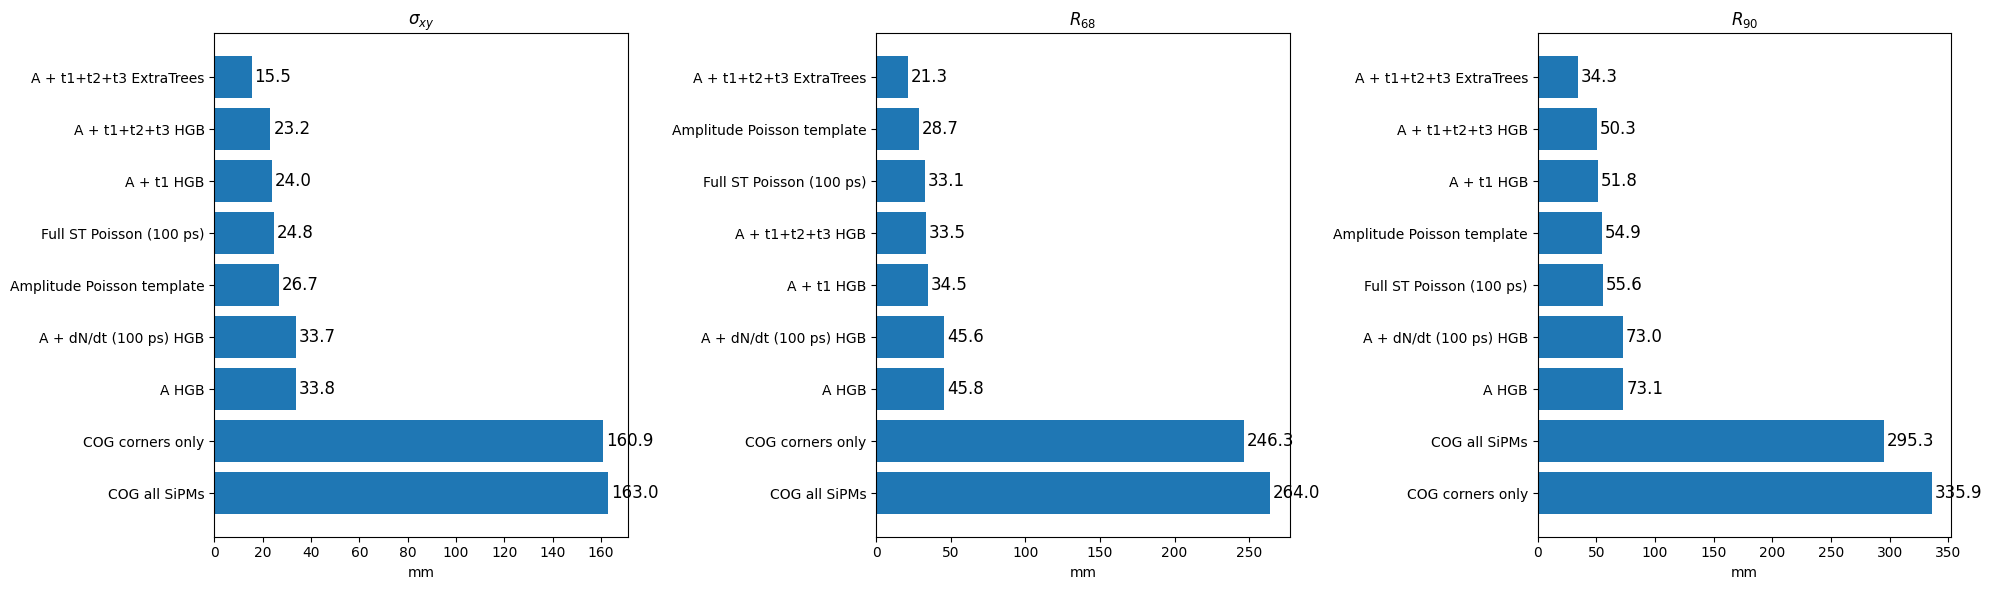

Best by R68: A + t1+t2+t3 ExtraTrees


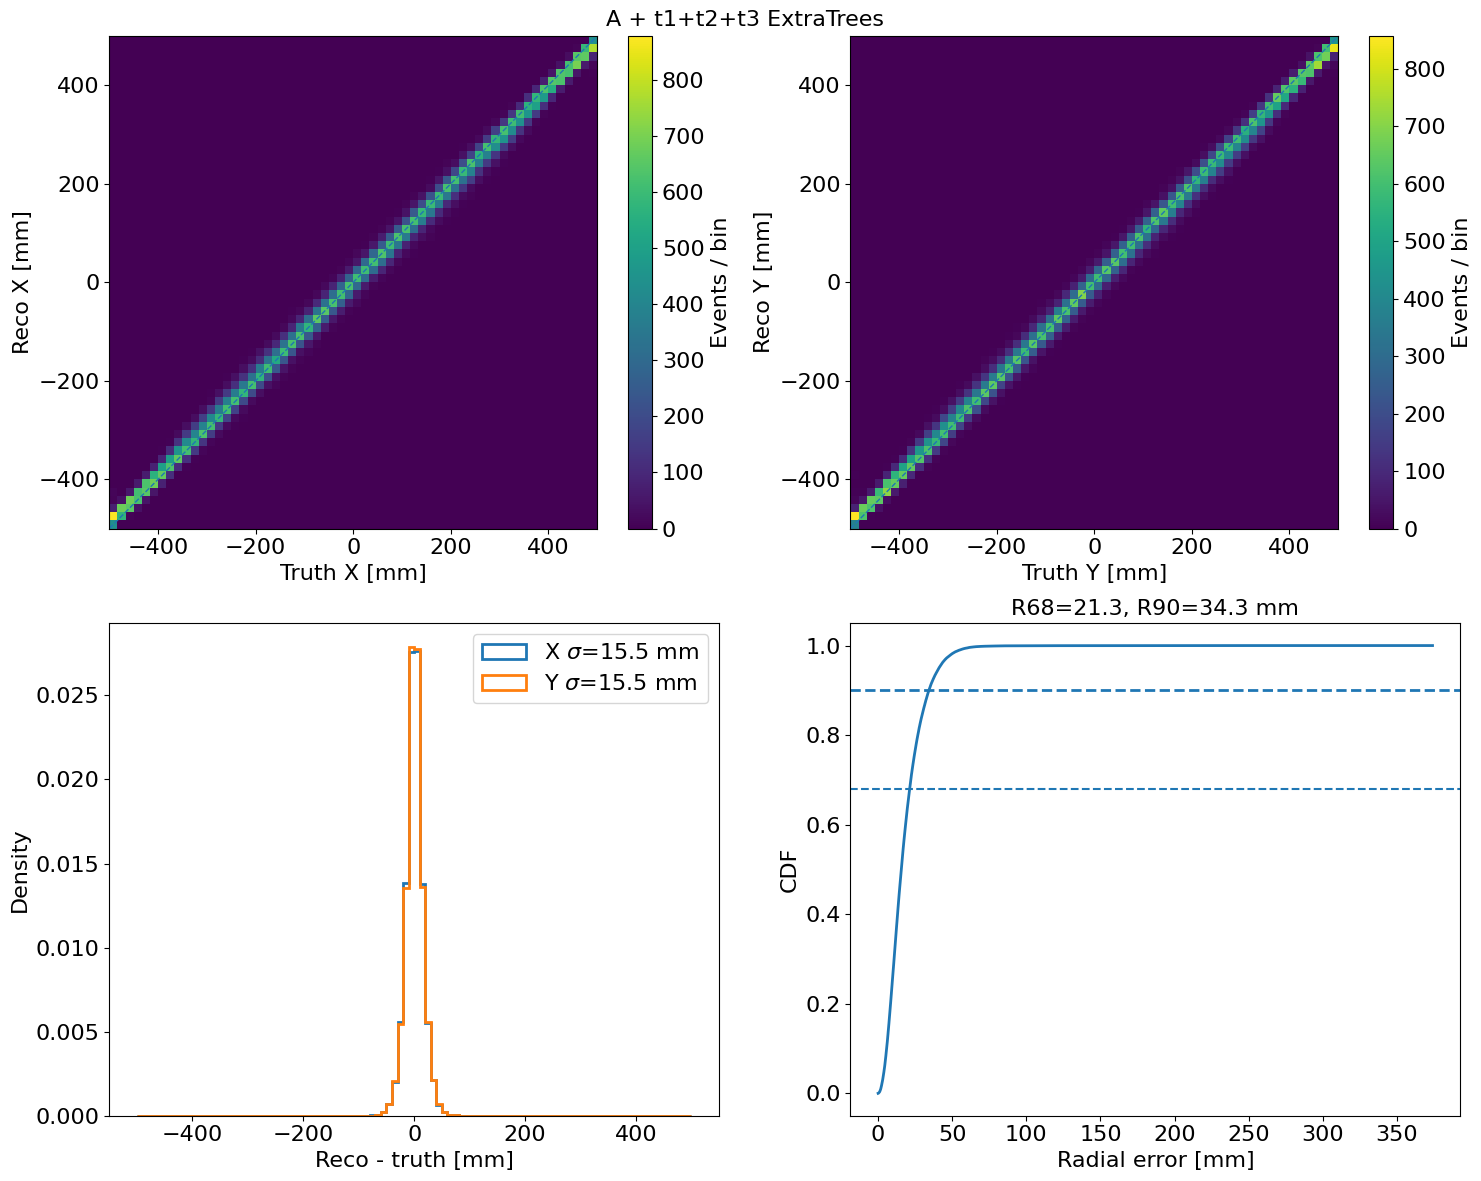

In [175]:

# 11. Summary + comparison
summary=pd.DataFrame([metrics(k,v) for k,v in pred.items()]).sort_values("R68_mm").reset_index(drop=True)
display(summary.round(2))
summary.to_csv(OUT/"spatiotemporal_reconstruction_summary.csv",index=False)

fig,ax=plt.subplots(1,3,figsize=(20,6))
for a,c,t in zip(ax,["sigma_xy_mm","R68_mm","R90_mm"],
                 [r"$\sigma_{xy}$",r"$R_{68}$",r"$R_{90}$"]):
    z=summary.sort_values(c)
    b=a.barh(z.method,z[c])
    a.bar_label(b,fmt="%.1f",padding=2,fontsize=12)
    a.invert_yaxis(); a.set(xlabel="mm",title=t)
plt.tight_layout()
plt.savefig(OUT/"reconstruction_comparison.png",dpi=180,bbox_inches="tight")
plt.show()

best=summary.iloc[0].method
print("Best by R68:",best)
performance(best,pred[best])


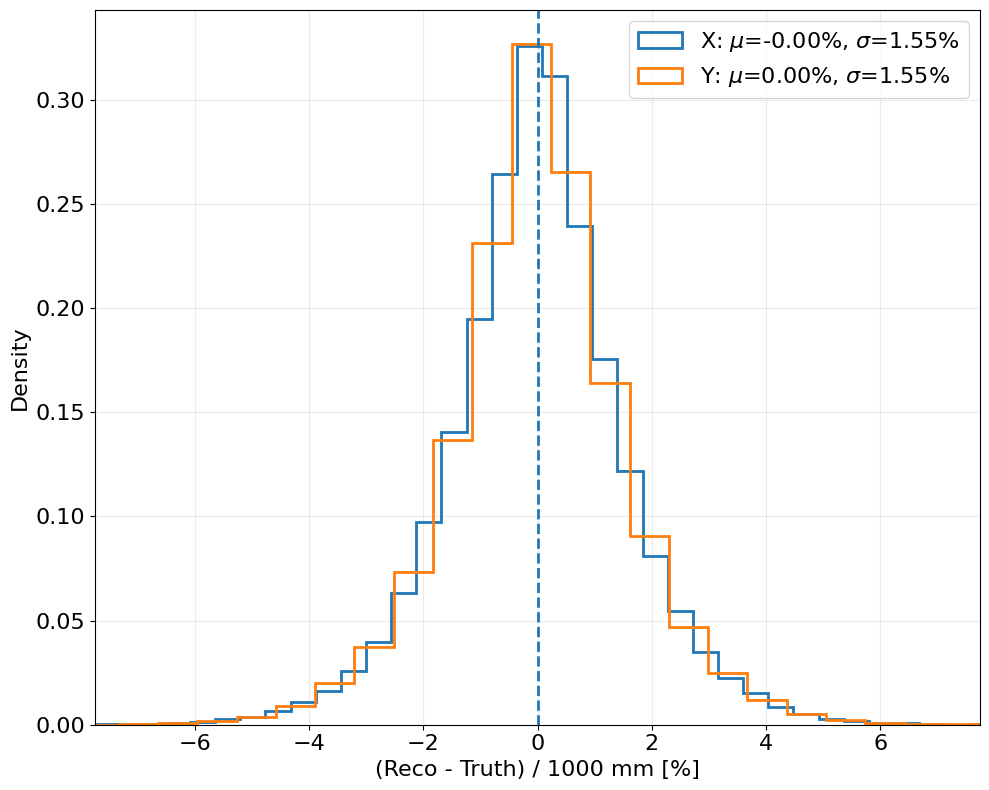

In [176]:
name=best
xy,tru=pred[name],truth[ite]
valid=np.isfinite(xy).all(1)
R=100*(xy[valid]-tru[valid])/LENGTH # detector size [mm]
s=max(float(np.sqrt(np.mean(R.std(0)**2))),1e-6)

fig,ax=plt.subplots(figsize=(10,8))

for j,l in enumerate("XY"):
    r=R[:,j]
    ax.hist(r,100,histtype="step",density=True,lw=2,
            label=fr"{l}: $\mu$={r.mean():.2f}%, $\sigma$={r.std():.2f}%")

ax.axvline(0,ls="--",lw=2)
ax.set(xlabel=f"(Reco - Truth) / {LENGTH} mm [%]",ylabel="Density",xlim=(-5*s,5*s))
ax.tick_params(labelsize=16)
ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16)
ax.legend(fontsize=16)

plt.tight_layout()
plt.grid(alpha=.25)
plt.savefig(OUT/"resolution_sigmaXY.png",dpi=180,bbox_inches="tight")
plt.show()


## 12. Information-limit check: approximate Poisson CRLB

For independent Poisson observables with expected response \(\mu_k(x,y)\),

$$
I_{ab}
=
\sum_k
\frac{1}{\mu_k}
\frac{\partial\mu_k}{\partial a}
\frac{\partial\mu_k}{\partial b},
\qquad a,b\in\{x,y\}.
$$

The inverse Fisher matrix provides a local lower-bound estimate.

This is an **approximate diagnostic**, especially for the timing representation because every event was aligned to its earliest detected photon. It is not a rigorous detector information limit: alignment introduces correlations, and finite calibration statistics can inflate numerical gradients. Use it as a model diagnostic; check calibration-size and grid-size stability before drawing conclusions about a 10 mm target.


Amplitude-only median CRLB sigma_xy: 10.40 mm
Full ST median CRLB sigma_xy: 0.26 mm
Full ST fraction of valid cells with CRLB < 10 mm: 100.0%
Finite ST CRLB cells: 1600


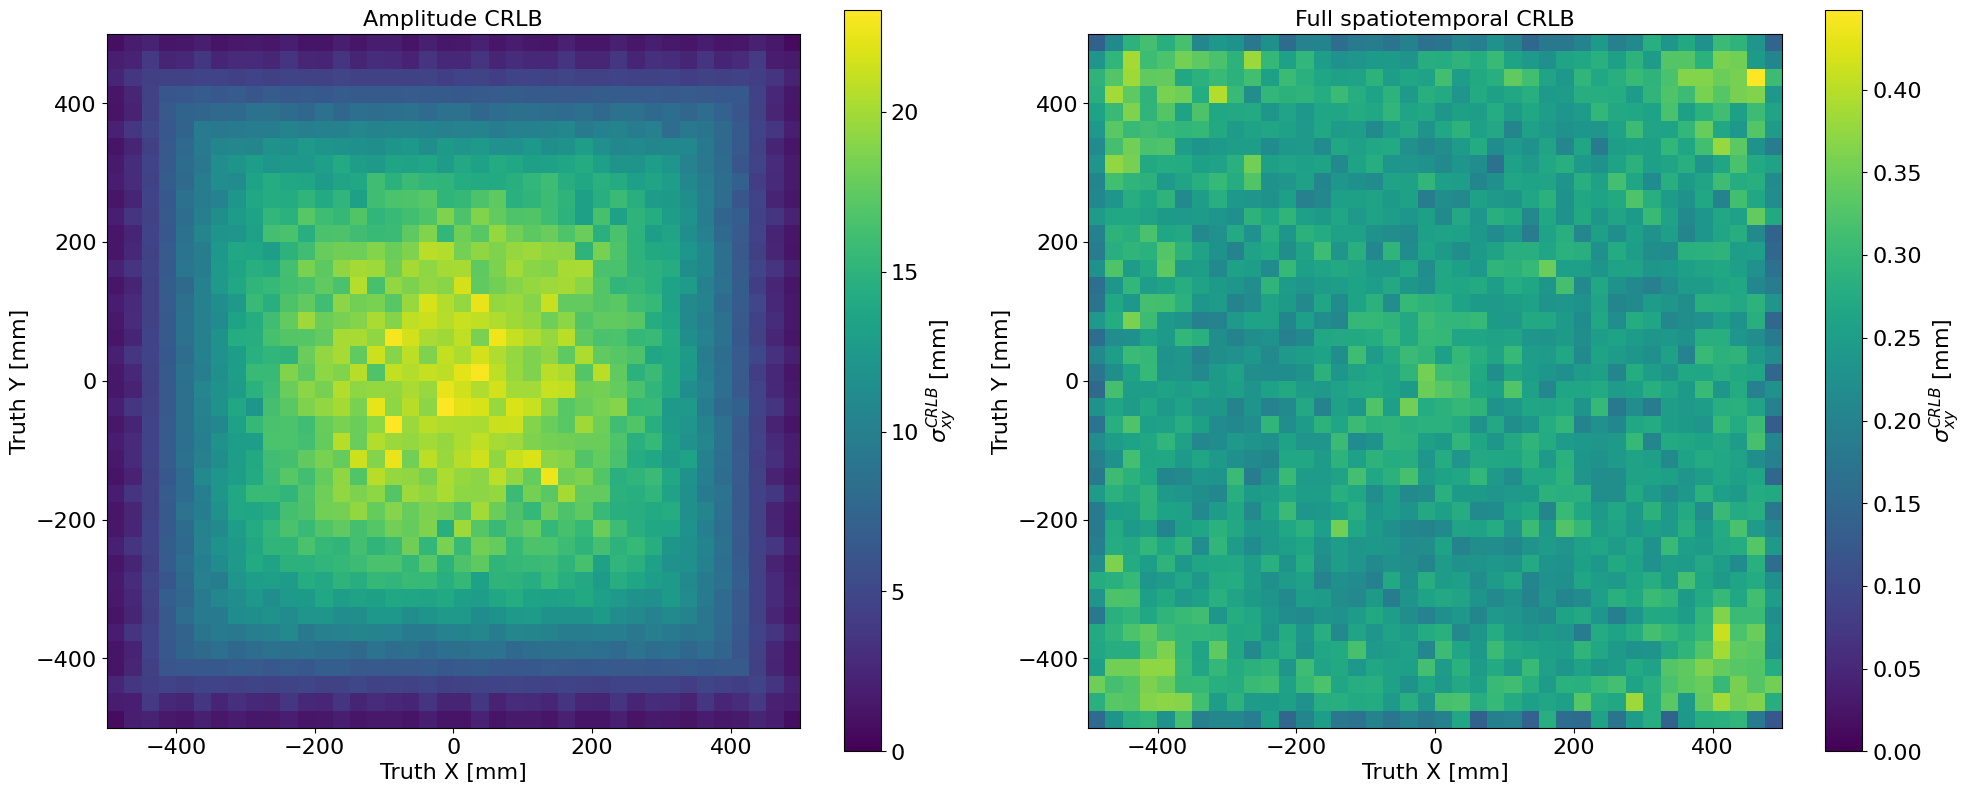

In [177]:

# 12. Approximate CRLB from a regular Poisson template grid
def crlb_map(mu_grid,count_grid,mincell=MIN_CELL):
    mu=np.array(mu_grid,float,copy=True)
    valid=(count_grid>=mincell)&np.isfinite(mu).all(2)

    mu[~valid]=np.nan  # exclude underpopulated neighbors from derivative stencils

    # NaNs deliberately propagate through gradients near missing cells
    dx=XY_CENTERS[1]-XY_CENTERS[0]
    dy=dx
    dmy,dmx=np.gradient(mu,dy,dx,axis=(0,1))

    lam=np.clip(mu,1e-6,None)
    Ixx=np.sum(dmx*dmx/lam,axis=2)
    Iyy=np.sum(dmy*dmy/lam,axis=2)
    Ixy=np.sum(dmx*dmy/lam,axis=2)

    det=Ixx*Iyy-Ixy*Ixy
    sx=np.full_like(Ixx,np.nan,float)
    sy=np.full_like(Iyy,np.nan,float)

    complete=np.isfinite(dmx).all(2)&np.isfinite(dmy).all(2)
    m=valid&complete&(Ixx>0)&(Iyy>0)&(det>1e-12*Ixx*Iyy)&np.isfinite(det)
    sx[m]=np.sqrt(Iyy[m]/det[m])
    sy[m]=np.sqrt(Ixx[m]/det[m])
    sxy=np.sqrt((sx*sx+sy*sy)/2)
    return sx,sy,sxy

sxA,syA,sxyA=crlb_map(muAgrid,countA)
sxST,syST,sxyST=crlb_map(muSTgrid,countST)

print("Amplitude-only median CRLB sigma_xy:",
      f"{np.nanmedian(sxyA):.2f} mm")
print("Full ST median CRLB sigma_xy:",
      f"{np.nanmedian(sxyST):.2f} mm")
print("Full ST fraction of valid cells with CRLB < 10 mm:",
      f"{np.mean(sxyST[np.isfinite(sxyST)]<10):.1%}" if np.isfinite(sxyST).any() else "unavailable")
# Invalid cells are excluded from the denominator.
print("Finite ST CRLB cells:",np.isfinite(sxyST).sum())

fig,ax=plt.subplots(1,2,figsize=(20,8))

for a,z,t in [(ax[0],sxyA,"Amplitude CRLB"),
              (ax[1],sxyST,"Full spatiotemporal CRLB")]:
    im=a.imshow(z,origin="lower",extent=(-HALF,HALF,-HALF,HALF),
                aspect="equal",vmin=0)
    a.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=t)
    a.tick_params(labelsize=16)
    a.xaxis.label.set_size(16); a.yaxis.label.set_size(16); a.title.set_size(16)

    c=plt.colorbar(im,ax=a)
    c.set_label(r"$\sigma_{xy}^{CRLB}$ [mm]",fontsize=16)
    c.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig(OUT/"approximate_CRLB_maps.png",dpi=180,bbox_inches="tight")
plt.show()


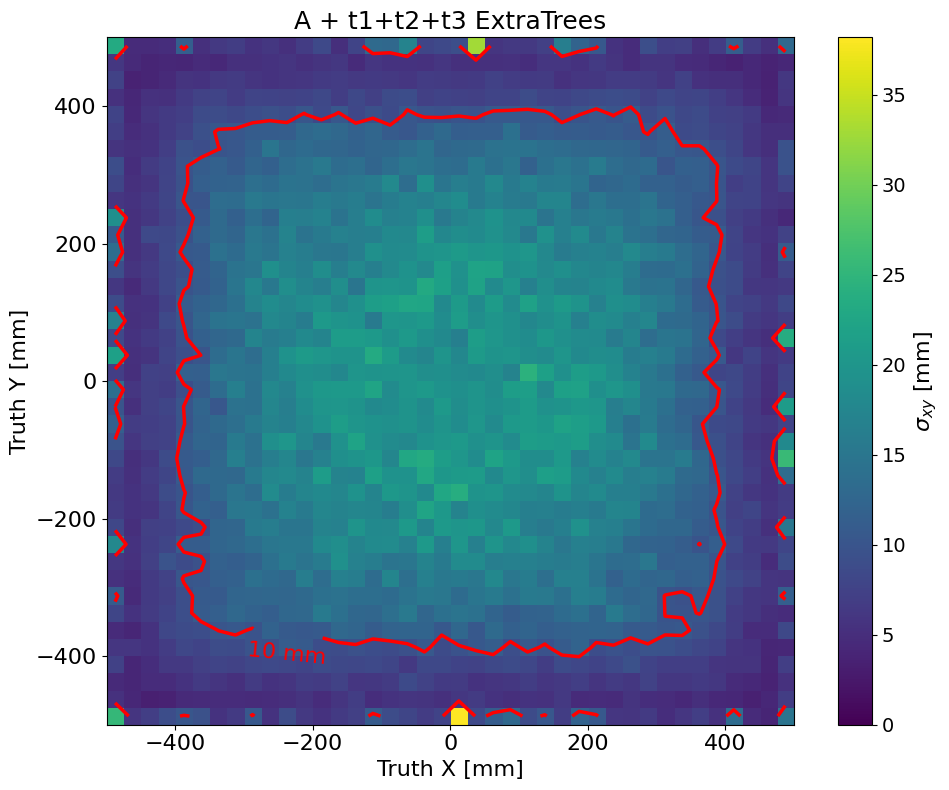

In [178]:
# 12b. Spatial resolution map — best model only

name=best
t,p=truth[ite],pred[name]
r=p-t


def local_error_maps(t,p):
    valid=np.isfinite(p).all(1)
    gid=grid_ids(t[valid]); residual=p[valid]-t[valid]
    ncell=GRID_N*GRID_N
    counts=np.bincount(gid,minlength=ncell)
    sums=np.column_stack([np.bincount(gid,weights=residual[:,j],minlength=ncell) for j in range(2)])
    sums2=np.column_stack([np.bincount(gid,weights=residual[:,j]**2,minlength=ncell) for j in range(2)])
    mean=np.divide(sums,counts[:,None],out=np.zeros_like(sums),where=counts[:,None]>0)
    second=np.divide(sums2,counts[:,None],out=np.zeros_like(sums2),where=counts[:,None]>0)
    variance=np.maximum(second-mean**2,0)
    maps=[np.sqrt(variance.mean(1)),np.sqrt((mean**2).mean(1)),np.sqrt(second.mean(1))]
    for z in maps: z[counts<MIN_CELL]=np.nan
    return tuple(z.reshape(GRID_N,GRID_N) for z in maps)

sxy,bias,rmse=local_error_maps(t,p)

def contour_10mm(ax,X,Y,z,fontsize):
    finite=z[np.isfinite(z)]
    if len(finite) and finite.min()<10<finite.max():
        cs=ax.contour(X,Y,z,levels=[10],colors="red",linewidths=2.5)
        ax.clabel(cs,fmt="10 mm",fontsize=fontsize)

fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(sxy,origin="lower",extent=(-HALF,HALF,-HALF,HALF),aspect="equal",vmin=0)

X,Y=np.meshgrid(XY_CENTERS,XY_CENTERS)
contour_10mm(ax,X,Y,sxy,16)

cbar=plt.colorbar(im,ax=ax)
cbar.set_label(r"$\sigma_{xy}$ [mm]",fontsize=16)
cbar.ax.tick_params(labelsize=14)
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=name)
# increase font size for axes and ticks, colorbar
ax.tick_params(labelsize=16)
ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16)
ax.title.set_size(18)
plt.tight_layout()
plt.savefig(OUT/"spatial_resolution_map_best.png",dpi=180,bbox_inches="tight")
plt.show()

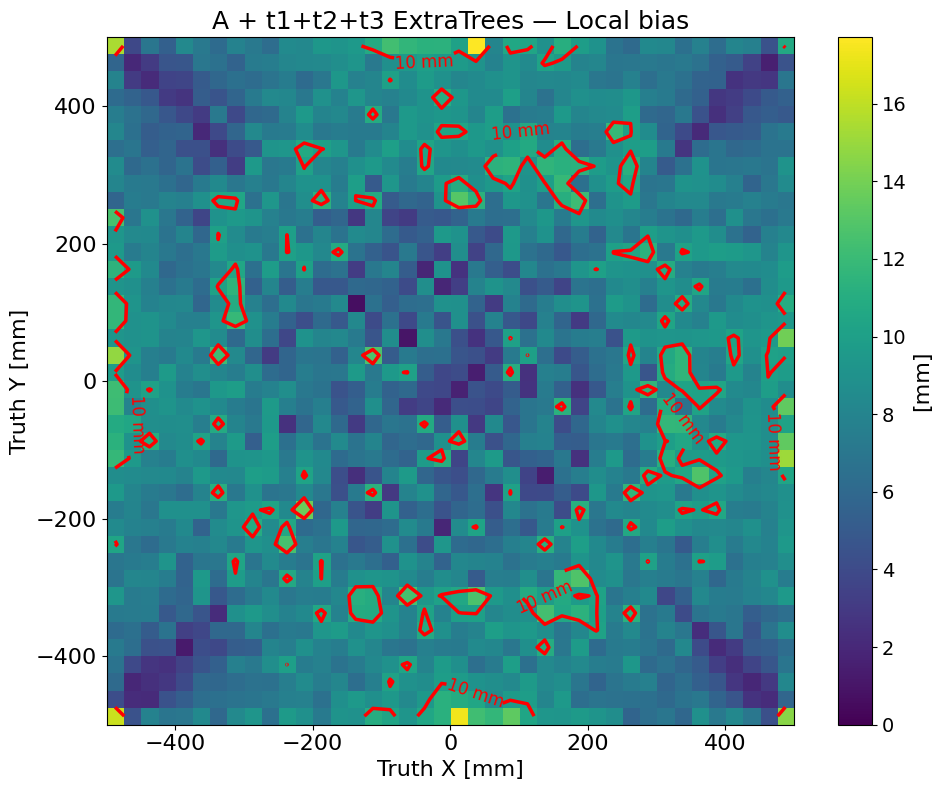

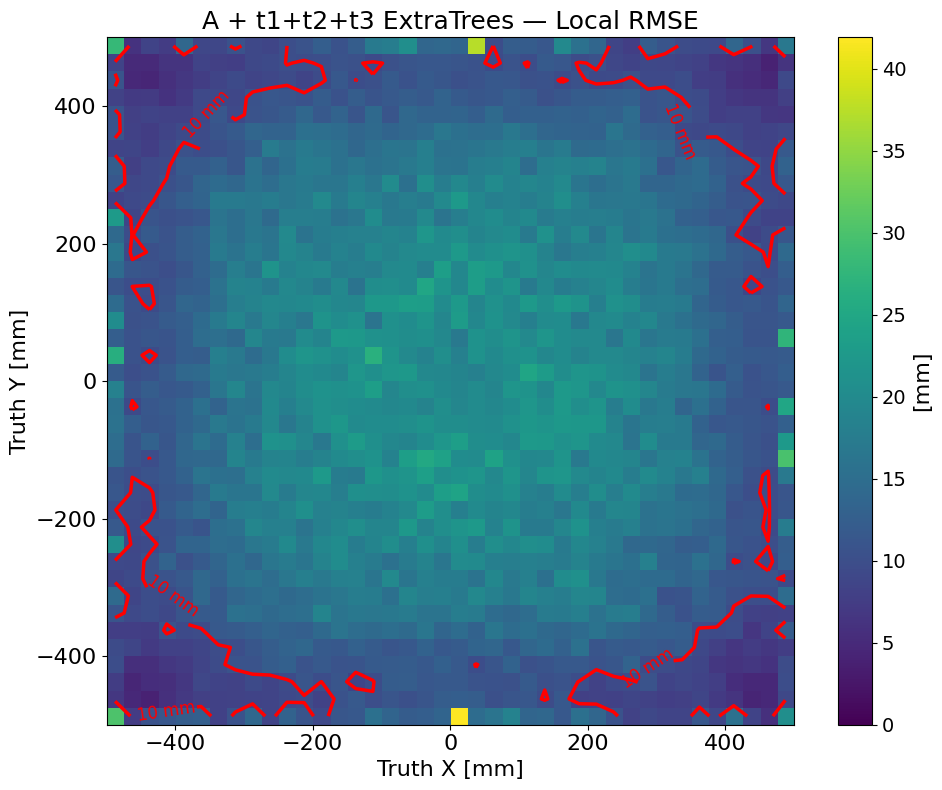

In [179]:
# 12c. Local bias / RMSE maps (computed together above)

for z,title in [(bias,"Local bias"),(rmse,"Local RMSE")]:
    fig,ax=plt.subplots(figsize=(10,8))
    im=ax.imshow(z,origin="lower",extent=(-HALF,HALF,-HALF,HALF),
                 aspect="equal",vmin=0)

    contour_10mm(ax,X,Y,z,12)

    cbar=plt.colorbar(im,ax=ax)
    cbar.set_label("[mm]",fontsize=16)
    cbar.ax.tick_params(labelsize=14)

    ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",
           title=f"{name} — {title}")
    ax.tick_params(labelsize=16)
    ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16)
    ax.title.set_size(18)
    plt.tight_layout()
    plt.show()


## 13. Optional \(dN/dt\) timing-bin scan

The master histogram is 50 ps/bin, so it can be rebinned without re-reading ROOT files.

Recommended factors:

- 1  \(\rightarrow\) 50 ps
- 2  \(\rightarrow\) 100 ps
- 4  \(\rightarrow\) 200 ps
- 6  \(\rightarrow\) 300 ps

This directly checks whether the current timing discretization is limiting the reconstruction.


50 ps R68 = 41.10 mm
100 ps R68 = 33.08 mm
200 ps R68 = 28.83 mm
300 ps R68 = 27.35 mm


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,50 ps,81000,1.0,30.07,0.02,0.00,30.19,29.94,30.07,41.10,68.83
1,100 ps,81000,1.0,24.81,0.08,-0.09,24.90,24.72,24.81,33.08,55.64
2,200 ps,81000,1.0,22.20,0.07,-0.17,22.26,22.14,22.20,28.83,49.01
3,300 ps,81000,1.0,21.26,0.10,-0.15,21.37,21.16,21.26,27.35,46.55


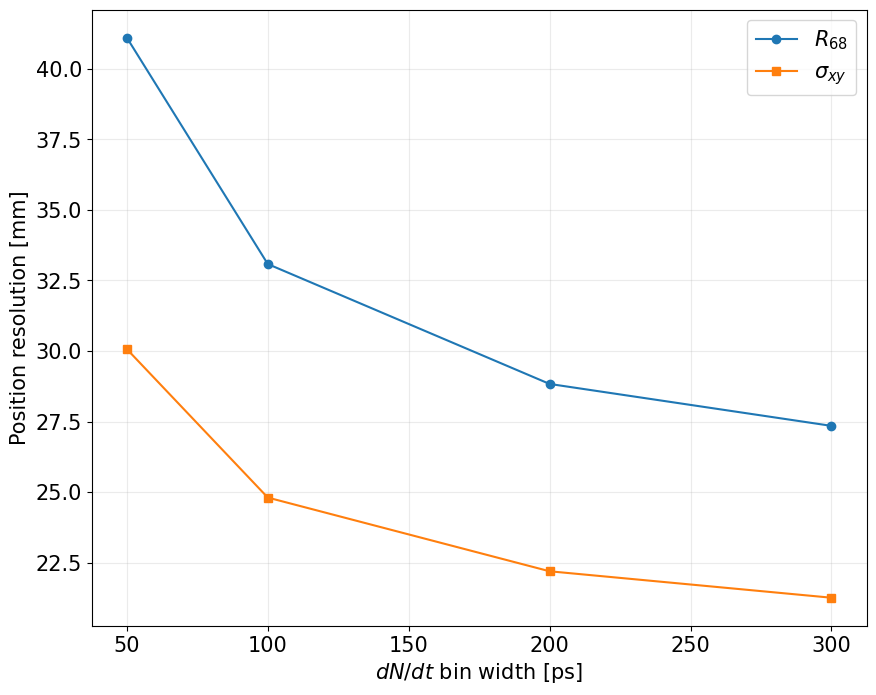

In [180]:
RUN_TIMING_BIN_SCAN=True
# 13. Optional timing-bin scan using full ST likelihood
if RUN_TIMING_BIN_SCAN:
    scan=[]
    for fac in [1,2,4,6]:
        if NBIN_FINE%fac: continue

        d=rebin_dnd(DND_FINE,fac)
        if fac==DND_REBIN:
            xy=pred[f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"]
        else:
            k=spatiotemporal_counts(d,A)
            p,m,counts,grid=build_templates(k)
            xy=poisson_reco(k[ite],p,m)
            del k,p,m,counts,grid
        del d
        met=metrics(f"{DT_FINE_NS*fac*1e3:.0f} ps",xy)
        scan.append(met)
        print(met["method"],"R68 =",f'{met["R68_mm"]:.2f} mm')

    scan=pd.DataFrame(scan)
    display(scan.round(2))
    scan.to_csv(OUT/"timing_bin_scan.csv",index=False)

    fig,ax=plt.subplots(figsize=(10,8))
    x=scan.method.str.replace(" ps","",regex=False).astype(float)
    ax.plot(x,scan.R68_mm,"o-",label=r"$R_{68}$")
    ax.plot(x,scan.sigma_xy_mm,"s-",label=r"$\sigma_{xy}$")
    ax.set(xlabel=r"$dN/dt$ bin width [ps]",ylabel="Position resolution [mm]")
    ax.tick_params(labelsize=15)
    ax.title.set_size(15)
    ax.xaxis.label.set_size(15)
    ax.yaxis.label.set_size(15)
    ax.grid(alpha=.25); ax.legend(fontsize=15)
    plt.savefig(OUT/"timing_bin_scan.png",dpi=180,bbox_inches="tight")
    plt.show()
else:
    print("RUN_TIMING_BIN_SCAN=False -> skipped")



# How to interpret the result

The most important progression is

$$
A
\rightarrow
A+t_1
\rightarrow
A+t_1+t_2+t_3
\rightarrow
A+dN/dt
\rightarrow
L_{\rm full\,ST}.
$$

Typical interpretations:

- **\(A+t_1\) improves strongly over amplitude**: propagation timing carries independent position information.
- **\(t_2,t_3\) add further improvement**: the early-photon order statistics are useful beyond the first photon.
- **\(dN/dt\) improves further**: waveform/arrival-time shape contains information that simple timing summaries discard.
- **Full ST likelihood improves over regression**: the detector response is well described by the calibrated photon space-time templates.
- **Approximate CRLB far above or below 10 mm**: investigate response-model assumptions, calibration statistics and grid-size stability before inferring detector limits or algorithmic headroom.


# 14. True detector timing-resolution scan
This scan is different from the \(dN/dt\) bin-width scan above.
For every detected photon, apply an independent Gaussian timestamp jitter
$$
t_{\rm meas}=t_{\rm Geant4}+\mathcal N(0,\sigma_t),
$$ where sigma_t is the assumed single-photon detector timing resolution.

$$
t_{\rm hit}^{\rm Geant4}
\rightarrow
t_{\rm hit}^{\rm smeared}
\rightarrow
t_0
\rightarrow
\Delta t
\rightarrow
t_1,t_2,t_3
\rightarrow
\text{ExtraTrees}$$

After smearing, both the event-wide reference time
$$
t_0=\min(t_{\rm meas})
$$ and the first/second/third photon ordering are recalculated. The amplitude information is unchanged.
Therefore this directly tests how the A + t1+t2+t3 ExtraTrees position resolution degrades as the detector timing resolution becomes worse.


   0 ps: sigma_xy=13.33 mm, R68=18.13 mm
  50 ps: sigma_xy=13.55 mm, R68=18.51 mm
 100 ps: sigma_xy=13.95 mm, R68=19.08 mm
 150 ps: sigma_xy=14.38 mm, R68=19.70 mm
 200 ps: sigma_xy=14.78 mm, R68=20.31 mm
 250 ps: sigma_xy=15.16 mm, R68=20.81 mm
 300 ps: sigma_xy=15.49 mm, R68=21.34 mm
 400 ps: sigma_xy=16.08 mm, R68=22.17 mm
 500 ps: sigma_xy=16.63 mm, R68=23.08 mm
 750 ps: sigma_xy=17.87 mm, R68=25.01 mm
1000 ps: sigma_xy=18.91 mm, R68=26.56 mm


,sigma_t_ps,sigma_xy_mm,R68_mm,R90_mm
0,0,13.33,18.13,29.52
1,50,13.55,18.51,29.98
2,100,13.95,19.08,30.84
3,150,14.38,19.70,31.80
4,200,14.78,20.31,32.73
5,250,15.16,20.81,33.70
6,300,15.49,21.34,34.31
7,400,16.08,22.17,35.53
8,500,16.63,23.08,36.54
9,750,17.87,25.01,38.91


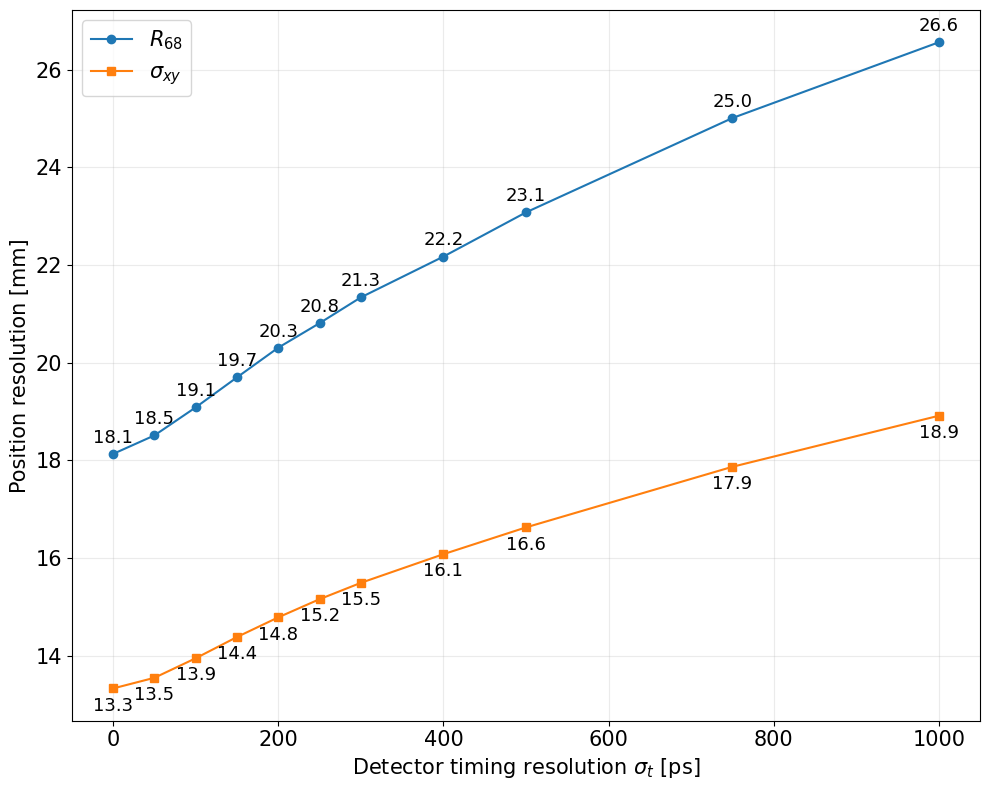

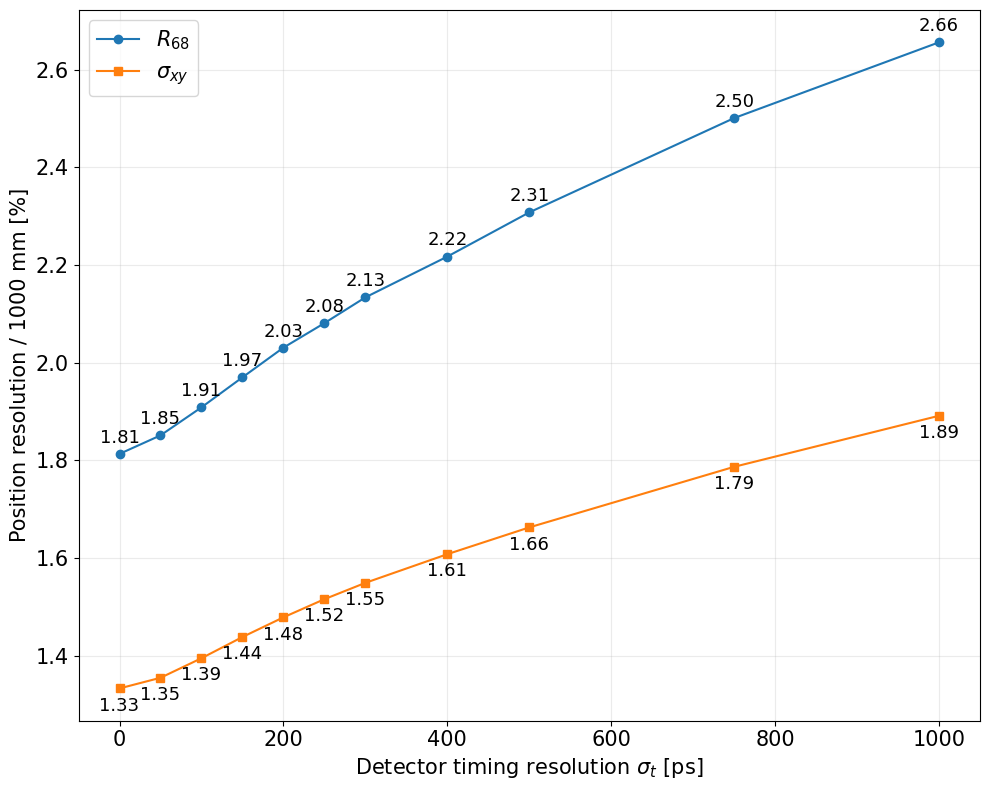

In [181]:
RUN_TRUE_TIMING_SCAN=True
# 14. Reuse exactly the same validated timing extraction as the main study
def smeared_T123(sigma_ps,seed=SEED+100):
    if sigma_ps<0: raise ValueError("Timing sigma must be nonnegative")
    rg=np.random.default_rng(seed)
    times=[np.full((len(good),NSIPM),np.nan,np.float32) for _ in range(3)]
    offset=0
    for fname in FILES:
        with uproot.open(fname) as f:
            et=f["events"]
            ev=integer_ids(et["event"].array(library="np") if "event" in et.keys()
                           else np.arange(et.num_entries),"events.event")
            row,sipm,tm=read_hit_arrays(f,ev)
            values=timing_features(row,sipm,tm,len(ev),sigma_ps,rg,with_dnd=False)
        for target,value in zip(times,values[:3]): target[offset:offset+len(ev)]=value
        offset+=len(ev)
    if offset!=len(good): raise ValueError("Input event count changed after loading")
    return tuple(t[good] for t in times)

if RUN_TRUE_TIMING_SCAN:
    scan_true=[]

    for sig in SIGMA_T_PS:
        t1,t2,t3=smeared_T123(sig)

        X=np.hstack([Afeat,t1,t2,t3])
        med=training_medians(X[itr_ml])
        X=np.where(np.isfinite(X),X,med)

        model=ExtraTreesRegressor(
            n_estimators=300,min_samples_leaf=2,max_features=.8,
            n_jobs=-1,random_state=SEED
        )
        model.fit(X[itr_ml],truth[itr_ml])
        xy=model.predict(X[ite])
        del model,X,t1,t2,t3

        m=metrics(f"{sig} ps",xy)
        m["sigma_t_ps"]=sig
        scan_true.append(m)

        print(f'{sig:4d} ps: sigma_xy={m["sigma_xy_mm"]:.2f} mm, '
              f'R68={m["R68_mm"]:.2f} mm')

    scan_true=pd.DataFrame(scan_true)
    display(scan_true[["sigma_t_ps","sigma_xy_mm","R68_mm","R90_mm"]].round(2))
    scan_true.to_csv(OUT/"true_detector_timing_resolution_scan.csv",index=False)

    fig,ax=plt.subplots(figsize=(10,8))

    ax.plot(scan_true.sigma_t_ps,scan_true.R68_mm,"o-",label=r"$R_{68}$")
    ax.plot(scan_true.sigma_t_ps,scan_true.sigma_xy_mm,"s-",label=r"$\sigma_{xy}$")

    for x,y in zip(scan_true.sigma_t_ps,scan_true.R68_mm):
        ax.annotate(f"{y:.1f}",(x,y),xytext=(0,8),
                    textcoords="offset points",ha="center",fontsize=13)

    for x,y in zip(scan_true.sigma_t_ps,scan_true.sigma_xy_mm):
        ax.annotate(f"{y:.1f}",(x,y),xytext=(0,-16),
                    textcoords="offset points",ha="center",fontsize=13)

    ax.set(xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
        ylabel="Position resolution [mm]")
    ax.tick_params(labelsize=15)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
    ax.grid(alpha=.25); ax.legend(fontsize=15)

    plt.tight_layout()
    plt.savefig(OUT/"true_detector_timing_resolution_scan.png",
                dpi=180,bbox_inches="tight")
    plt.show()

    scan_true["R68_pct"]=100*scan_true.R68_mm/LENGTH
    scan_true["sigma_pct"]=100*scan_true.sigma_xy_mm/LENGTH
    fig,ax=plt.subplots(figsize=(10,8))
    ax.plot(scan_true.sigma_t_ps,scan_true.R68_pct,"o-",label=r"$R_{68}$")
    ax.plot(scan_true.sigma_t_ps,scan_true.sigma_pct,"s-",label=r"$\sigma_{xy}$")
    for x,y in zip(scan_true.sigma_t_ps,scan_true.R68_pct):
        ax.annotate(f"{y:.2f}",(x,y),xytext=(0,8),
                    textcoords="offset points",ha="center",fontsize=13)
    for x,y in zip(scan_true.sigma_t_ps,scan_true.sigma_pct):
        ax.annotate(f"{y:.2f}",(x,y),xytext=(0,-16),
                    textcoords="offset points",ha="center",fontsize=13)
    ax.set(xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
        ylabel=f"Position resolution / {LENGTH} mm [%]")
    ax.tick_params(labelsize=15)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
    ax.grid(alpha=.25); ax.legend(fontsize=15)
    plt.tight_layout()
    plt.savefig(OUT/f"true_detector_timing_resolution_relative_{LENGTH}.png",
                dpi=180,bbox_inches="tight")
    plt.show()
else:
    print("RUN_TRUE_TIMING_SCAN=False -> skipped")